# Vox Deorum Analysis: Strategist Comparison

This notebook analyzes game results comparing different strategist conditions (excluding none-strategist).

In [41]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Import utility functions and CONDITION_MAPPING from the plot-utilities module
from shared.plot_utilities import (
    load_panel_data,
    setup_notebook_display,
    plot_bar_chart,
    plot_grouped_bar_chart,
    plot_distribution_histograms,
    plot_strategy_radar_charts
)

# Set up notebook display and plotting style
setup_notebook_display(figsize=(10, 6))

# Load panel data using the unified function
panel_df = load_panel_data('../panel_data.csv', exclude_non_llm=False)
panel_df.head()

✓ Loaded panel data: 4408 rows
✓ Unique conditions: 15
✓ Unique player types: 16

Player Type Distribution:
  Vanilla: 2534 rows (57.5%)
  Null: 200 rows (4.5%)
  GLM-4.7-Simple: 179 rows (4.1%)
  GLM-4.7-Briefed: 179 rows (4.1%)
  Kimi-K2.5-Briefed: 167 rows (3.8%)
  Kimi-K2.5-Simple: 167 rows (3.8%)
  GPT-OSS-120B-Simple: 156 rows (3.5%)
  GPT-OSS-120B-Briefed: 156 rows (3.5%)
  Minimax-M2.5-Simple: 118 rows (2.7%)
  Minimax-M2.5-Briefed: 118 rows (2.7%)
  Deepseek-3.2-Simple: 113 rows (2.6%)
  Deepseek-3.2-Briefed: 113 rows (2.6%)
  Qwen-3.5-Briefed: 76 rows (1.7%)
  Qwen-3.5-Simple: 76 rows (1.7%)
  Sonnet-4.5-Briefed: 28 rows (0.6%)
  Sonnet-4.5-Simple: 28 rows (0.6%)

Condition Distribution:
  observe-vanilla-standard: 1552 rows (35.2%)
  2026-deepseek-v-kimi2-v-glm-standard: 656 rows (14.9%)
  2026-oss-v-glm-standard: 528 rows (12.0%)
  2026-null-ai-standard: 400 rows (9.1%)
  2026-qwen-v-kimi2-v-minimax-standard: 328 rows (7.4%)
  2026-oss-v-qwen-v-minimax-standard: 280 rows (6

,experiment,game_id,turn,map_type,map_size,difficulty,game_speed,victory_type,victory_player_id,player_id,civilization,score,score_rank,score_ratio,survival_turn,is_winner,input_tokens,reasoning_tokens,output_tokens,strategy_changes,persona_changes,research_changes,policy_changes,nuke,use_nuke,domination_ratio,culture_ratio,diplomatic_ratio,science_ratio,tradition,authority,progress,fealty,statecraft,artistry,industry,imperialism,rationalism,freedom,autocracy,order,condition,player_type
0,2026-deepseek-v-kimi-v-glm-standard,085cfce3-75ee-4459-b7b0-c49c9a27f651,415,Vox_Deorum,Standard,Prince,Standard,Science,3,0,Polynesia,1543,7,0.3550,415,0,0.0,0.0,0.0,191,1,0,0,NaN,NaN,0.3614,0.1205,0.2530,0.2651,NaN,NaN,18.0,NaN,147.0,NaN,NaN,243.0,NaN,NaN,NaN,326.0,2026-deepseek-v-kimi-v-glm-standard,Vanilla
1,2026-deepseek-v-kimi-v-glm-standard,085cfce3-75ee-4459-b7b0-c49c9a27f651,415,Vox_Deorum,Standard,Prince,Standard,Science,3,1,Austria,2643,3,0.6080,415,0,0.0,0.0,0.0,220,1,0,0,50.0,50.0,0.0000,0.0240,0.5288,0.4471,NaN,NaN,17.0,132.0,NaN,NaN,224.0,NaN,NaN,318.0,NaN,NaN,2026-deepseek-v-kimi-v-glm-standard,Vanilla
2,2026-deepseek-v-kimi-v-glm-standard,085cfce3-75ee-4459-b7b0-c49c9a27f651,415,Vox_Deorum,Standard,Prince,Standard,Science,3,2,Babylon,1402,8,0.3225,415,0,13700445.0,1213318.0,230753.0,251,65,65,47,NaN,NaN,0.0000,0.1226,0.0120,0.8654,18.0,NaN,28.0,211.0,NaN,257.0,300.0,346.0,279.0,NaN,NaN,363.0,2026-deepseek-v-kimi-v-glm-standard,Kimi-K2.5-Simple
3,2026-deepseek-v-kimi-v-glm-standard,085cfce3-75ee-4459-b7b0-c49c9a27f651,415,Vox_Deorum,Standard,Prince,Standard,Science,3,3,Portugal,4196,2,0.9653,415,1,29105306.0,1695836.0,2678364.0,304,75,91,76,40.0,40.0,0.0000,0.0120,0.9760,0.0120,113.0,NaN,16.0,NaN,126.0,NaN,237.0,NaN,225.0,NaN,NaN,290.0,2026-deepseek-v-kimi-v-glm-standard,Kimi-K2.5-Briefed
4,2026-deepseek-v-kimi-v-glm-standard,085cfce3-75ee-4459-b7b0-c49c9a27f651,415,Vox_Deorum,Standard,Prince,Standard,Science,3,4,Mongolia,2466,4,0.5673,415,0,14763017.0,811214.0,260286.0,214,99,94,57,100.0,100.0,1.0000,0.0000,0.0000,0.0000,200.0,16.0,126.0,220.0,259.0,178.0,366.0,296.0,346.0,NaN,366.0,NaN,2026-deepseek-v-kimi-v-glm-standard,GLM-4.7-Simple


In [42]:
# Quick dataset summary: LLM games and players
llm_mask = ~panel_df['player_type'].isin(['Vanilla', 'Null'])
llm_players = panel_df.loc[llm_mask]

# Games that have at least one LLM player
llm_game_ids = llm_players['game_id'].unique()

print(f"Total rows: {len(panel_df):,}")
print(f"Total unique games: {panel_df['game_id'].nunique():,}")
print(f"Games with LLM players: {len(llm_game_ids):,}")
print(f"LLM player rows: {len(llm_players):,}")
print(f"Unique LLM player types: {llm_players['player_type'].nunique()}")
print(f"LLM player types: {sorted(llm_players['player_type'].unique())}")

Total rows: 4,408
Total unique games: 551
Games with LLM players: 307
LLM player rows: 1,674
Unique LLM player types: 14
LLM player types: ['Deepseek-3.2-Briefed', 'Deepseek-3.2-Simple', 'GLM-4.7-Briefed', 'GLM-4.7-Simple', 'GPT-OSS-120B-Briefed', 'GPT-OSS-120B-Simple', 'Kimi-K2.5-Briefed', 'Kimi-K2.5-Simple', 'Minimax-M2.5-Briefed', 'Minimax-M2.5-Simple', 'Qwen-3.5-Briefed', 'Qwen-3.5-Simple', 'Sonnet-4.5-Briefed', 'Sonnet-4.5-Simple']


## 1. Win Rate of Each Player by Condition

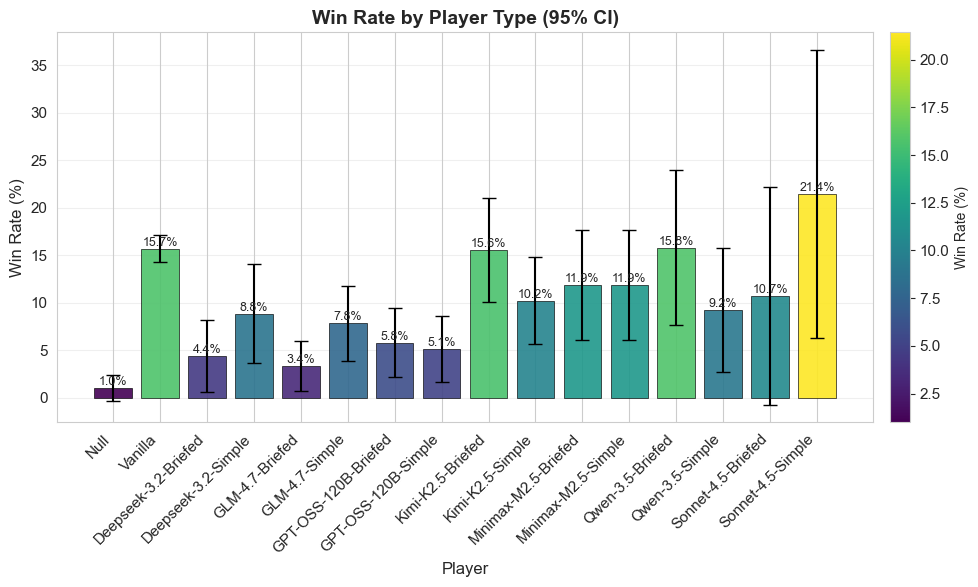

,is_winner=1
Null,2/200 (1.0%)
Vanilla,398/2534 (15.7%)
Deepseek-3.2-Briefed,5/113 (4.4%)
Deepseek-3.2-Simple,10/113 (8.8%)
GLM-4.7-Briefed,6/179 (3.4%)
GLM-4.7-Simple,14/179 (7.8%)
GPT-OSS-120B-Briefed,9/156 (5.8%)
GPT-OSS-120B-Simple,8/156 (5.1%)
Kimi-K2.5-Briefed,26/167 (15.6%)
Kimi-K2.5-Simple,17/167 (10.2%)


In [43]:
# Create the chart and print summary  
plot_bar_chart(
    panel_df,
    value_col='is_winner',
    category_col='player_type',
    xlabel='Player',
    ylabel='Win Rate (%)',
    title='Win Rate by Player Type',
    use_percentage=True,
    show_error_bars=True
)

## 2. Victory Type Distribution by Condition

Analyzing the types of victories (Cultural, Diplomatic, Domination, Science, Time) across conditions.

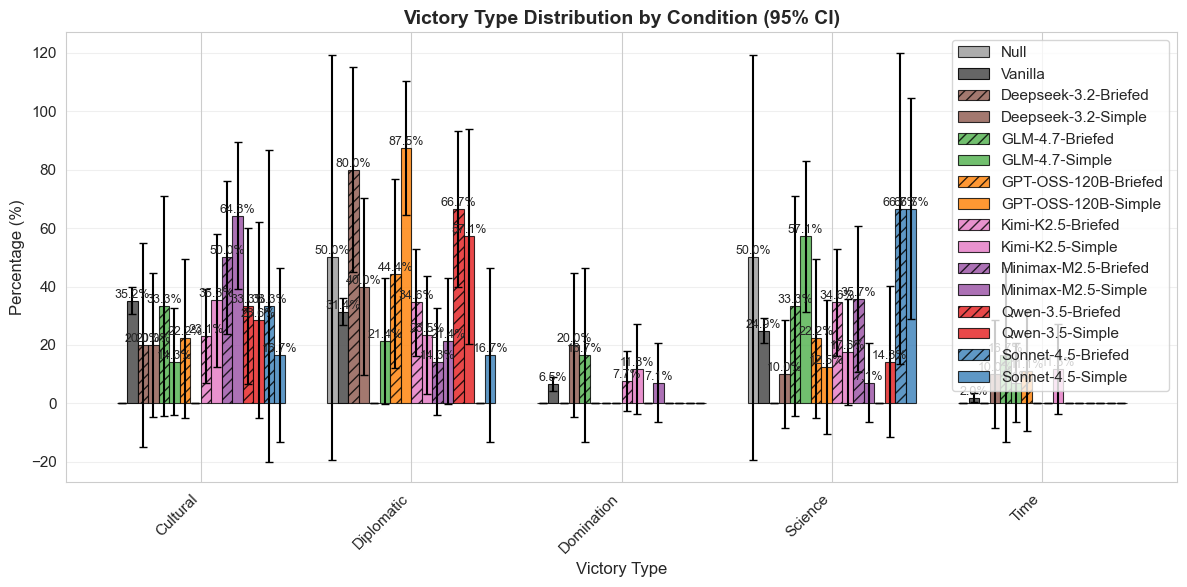

victory_type,Cultural,Diplomatic,Domination,Science,Time
Deepseek-3.2-Briefed,1 (20.0%),4 (80.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Deepseek-3.2-Simple,2 (20.0%),4 (40.0%),2 (20.0%),1 (10.0%),1 (10.0%)
GLM-4.7-Briefed,2 (33.3%),0 (0.0%),1 (16.7%),2 (33.3%),1 (16.7%)
GLM-4.7-Simple,2 (14.3%),3 (21.4%),0 (0.0%),8 (57.1%),1 (7.1%)
GPT-OSS-120B-Briefed,2 (22.2%),4 (44.4%),0 (0.0%),2 (22.2%),1 (11.1%)
GPT-OSS-120B-Simple,0 (0.0%),7 (87.5%),0 (0.0%),1 (12.5%),0 (0.0%)
Kimi-K2.5-Briefed,6 (23.1%),9 (34.6%),2 (7.7%),9 (34.6%),0 (0.0%)
Kimi-K2.5-Simple,6 (35.3%),4 (23.5%),2 (11.8%),3 (17.6%),2 (11.8%)
Minimax-M2.5-Briefed,7 (50.0%),2 (14.3%),0 (0.0%),5 (35.7%),0 (0.0%)
Minimax-M2.5-Simple,9 (64.3%),3 (21.4%),1 (7.1%),1 (7.1%),0 (0.0%)


In [44]:
# Victory type distribution
plot_grouped_bar_chart(
    panel_df[panel_df["is_winner"] == 1],
    value_col=None,  # Not used when use_percentage=True
    category_col='victory_type',
    xlabel='Victory Type',
    ylabel='Percentage (%)',
    title='Victory Type Distribution by Condition',
    use_percentage=True,
    show_error_bars=True,
    rotation=45
)

## 3. Choice of Ideology

C:\Users\John Chen\AppData\Local\Temp\ipykernel_185336\1159868436.py:5: FutureWarning: The behavior of DataFrame.idxmin with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  .idxmin(axis=1)


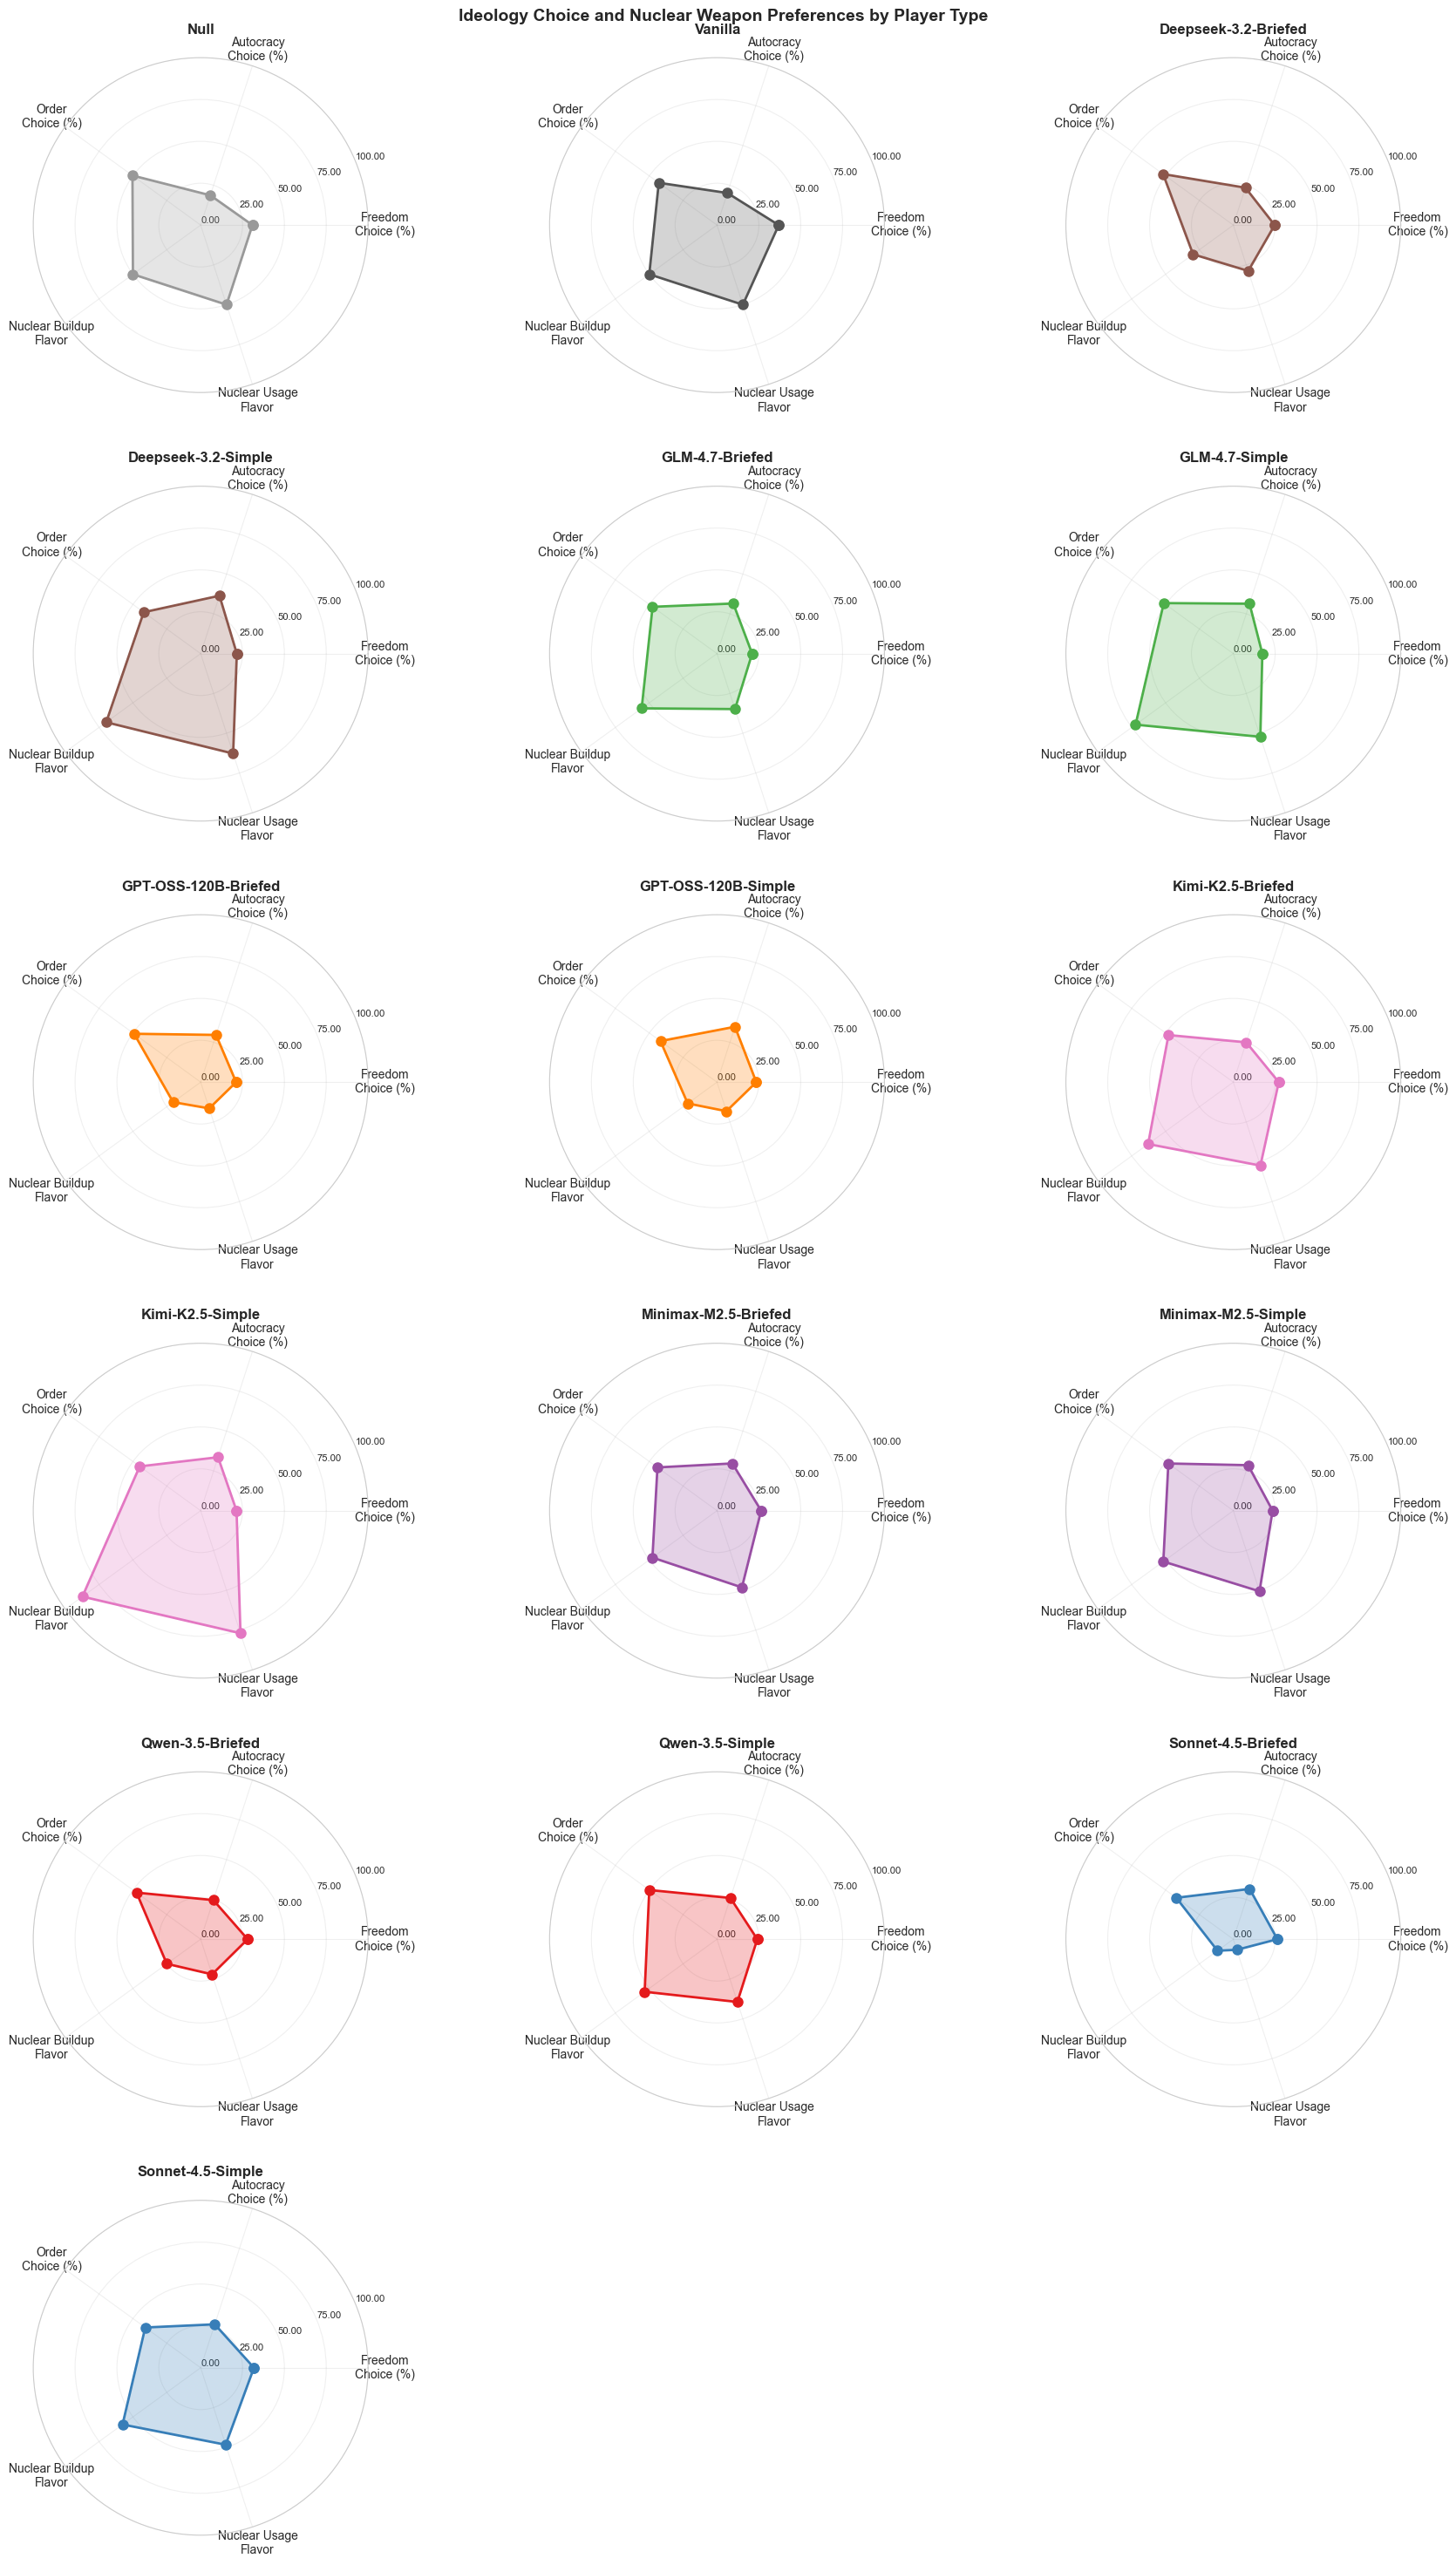


Ideology Choice and Nuclear Weapon Preferences by Player Type Summary:


c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2304: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2305: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc


,N,Freedom Choice (%),Autocracy Choice (%),Order Choice (%),Nuclear Buildup Flavor,Nuclear Usage Flavor
Null,200,"30.935 [23.155, 38.715]","18.705 [12.141, 25.269]","50.360 [41.944, 58.775]","50.000 [nan, nan]","50.000 [nan, nan]"
Vanilla,2534,"36.870 [34.778, 38.963]","20.147 [18.407, 21.887]","42.983 [40.835, 45.130]","50.000 [nan, nan]","50.000 [nan, nan]"
Deepseek-3.2-Briefed,113,"24.691 [15.097, 34.286]","23.457 [14.029, 32.885]","51.852 [40.735, 62.969]","29.697 [19.997, 39.397]","28.788 [19.302, 38.274]"
Deepseek-3.2-Simple,113,"21.591 [12.823, 30.359]","36.364 [26.113, 46.614]","42.045 [31.526, 52.564]","69.737 [57.076, 82.398]","62.763 [49.534, 75.992]"
GLM-4.7-Briefed,179,"20.979 [14.225, 27.733]","31.469 [23.765, 39.172]","47.552 [39.268, 55.837]","55.609 [48.393, 62.824]","34.826 [28.684, 40.968]"
GLM-4.7-Simple,179,"17.333 [11.206, 23.461]","31.333 [23.824, 38.842]","51.333 [43.242, 59.425]","72.174 [66.002, 78.345]","52.250 [46.391, 58.109]"
GPT-OSS-120B-Briefed,156,"21.186 [13.705, 28.668]","29.661 [21.298, 38.024]","49.153 [39.999, 58.306]","20.312 [16.050, 24.575]","16.484 [12.878, 20.091]"
GPT-OSS-120B-Simple,156,"23.478 [15.614, 31.342]","34.783 [25.946, 43.619]","41.739 [32.590, 50.888]","21.618 [15.596, 27.640]","18.235 [13.051, 23.420]"
Kimi-K2.5-Briefed,167,"27.143 [19.685, 34.601]","25.000 [17.738, 32.262]","47.857 [39.480, 56.235]","62.889 [56.409, 69.369]","52.389 [46.248, 58.530]"
Kimi-K2.5-Simple,167,"21.429 [14.547, 28.310]","33.571 [25.652, 41.491]","45.000 [36.657, 53.343]","87.312 [82.510, 92.115]","76.975 [70.302, 83.648]"


(<Figure size 1800x3000 with 18 Axes>,
 array([<PolarAxes: title={'center': 'Null'}>,
        <PolarAxes: title={'center': 'Vanilla'}>,
        <PolarAxes: title={'center': 'Deepseek-3.2-Briefed'}>,
        <PolarAxes: title={'center': 'Deepseek-3.2-Simple'}>,
        <PolarAxes: title={'center': 'GLM-4.7-Briefed'}>,
        <PolarAxes: title={'center': 'GLM-4.7-Simple'}>,
        <PolarAxes: title={'center': 'GPT-OSS-120B-Briefed'}>,
        <PolarAxes: title={'center': 'GPT-OSS-120B-Simple'}>,
        <PolarAxes: title={'center': 'Kimi-K2.5-Briefed'}>,
        <PolarAxes: title={'center': 'Kimi-K2.5-Simple'}>,
        <PolarAxes: title={'center': 'Minimax-M2.5-Briefed'}>,
        <PolarAxes: title={'center': 'Minimax-M2.5-Simple'}>,
        <PolarAxes: title={'center': 'Qwen-3.5-Briefed'}>,
        <PolarAxes: title={'center': 'Qwen-3.5-Simple'}>,
        <PolarAxes: title={'center': 'Sonnet-4.5-Briefed'}>,
        <PolarAxes: title={'center': 'Sonnet-4.5-Simple'}>, <PolarAxes: >,
  

In [45]:
# Choice of ideology (first adopted among freedom/autocracy/order)
ideology_cols = ['freedom', 'autocracy', 'order']
panel_df['ideology_choice'] = (
    panel_df[ideology_cols]
    .idxmin(axis=1)
    .where(panel_df[ideology_cols].notna().any(axis=1), None)
    .str.title()
)

# Create binary columns for each ideology choice (0-100 scale to match nuclear flavors)
# Only set values for games where an ideology was actually adopted
panel_df['freedom_pct'] = None
panel_df['autocracy_pct'] = None
panel_df['order_pct'] = None

# Only calculate for games with ideology choice
ideology_mask = panel_df['ideology_choice'].notna()
panel_df.loc[ideology_mask, 'freedom_pct'] = (panel_df.loc[ideology_mask, 'ideology_choice'] == 'Freedom').astype(float) * 100
panel_df.loc[ideology_mask, 'autocracy_pct'] = (panel_df.loc[ideology_mask, 'ideology_choice'] == 'Autocracy').astype(float) * 100
panel_df.loc[ideology_mask, 'order_pct'] = (panel_df.loc[ideology_mask, 'ideology_choice'] == 'Order').astype(float) * 100

# Create radar chart showing ideology choices and nuclear flavors by player type
plot_strategy_radar_charts(
    panel_df,
    columns=['freedom_pct', 'autocracy_pct', 'order_pct', 'nuke', 'use_nuke'],
    labels=['Freedom\nChoice (%)', 'Autocracy\nChoice (%)', 'Order\nChoice (%)', 
            'Nuclear Buildup\nFlavor', 'Nuclear Usage\nFlavor'],
    title='Ideology Choice and Nuclear Weapon Preferences by Player Type',
    ylim=(0, 100),
    print_summary=True
)

## 4. Survival Rate (Survival Turns / Game Length)

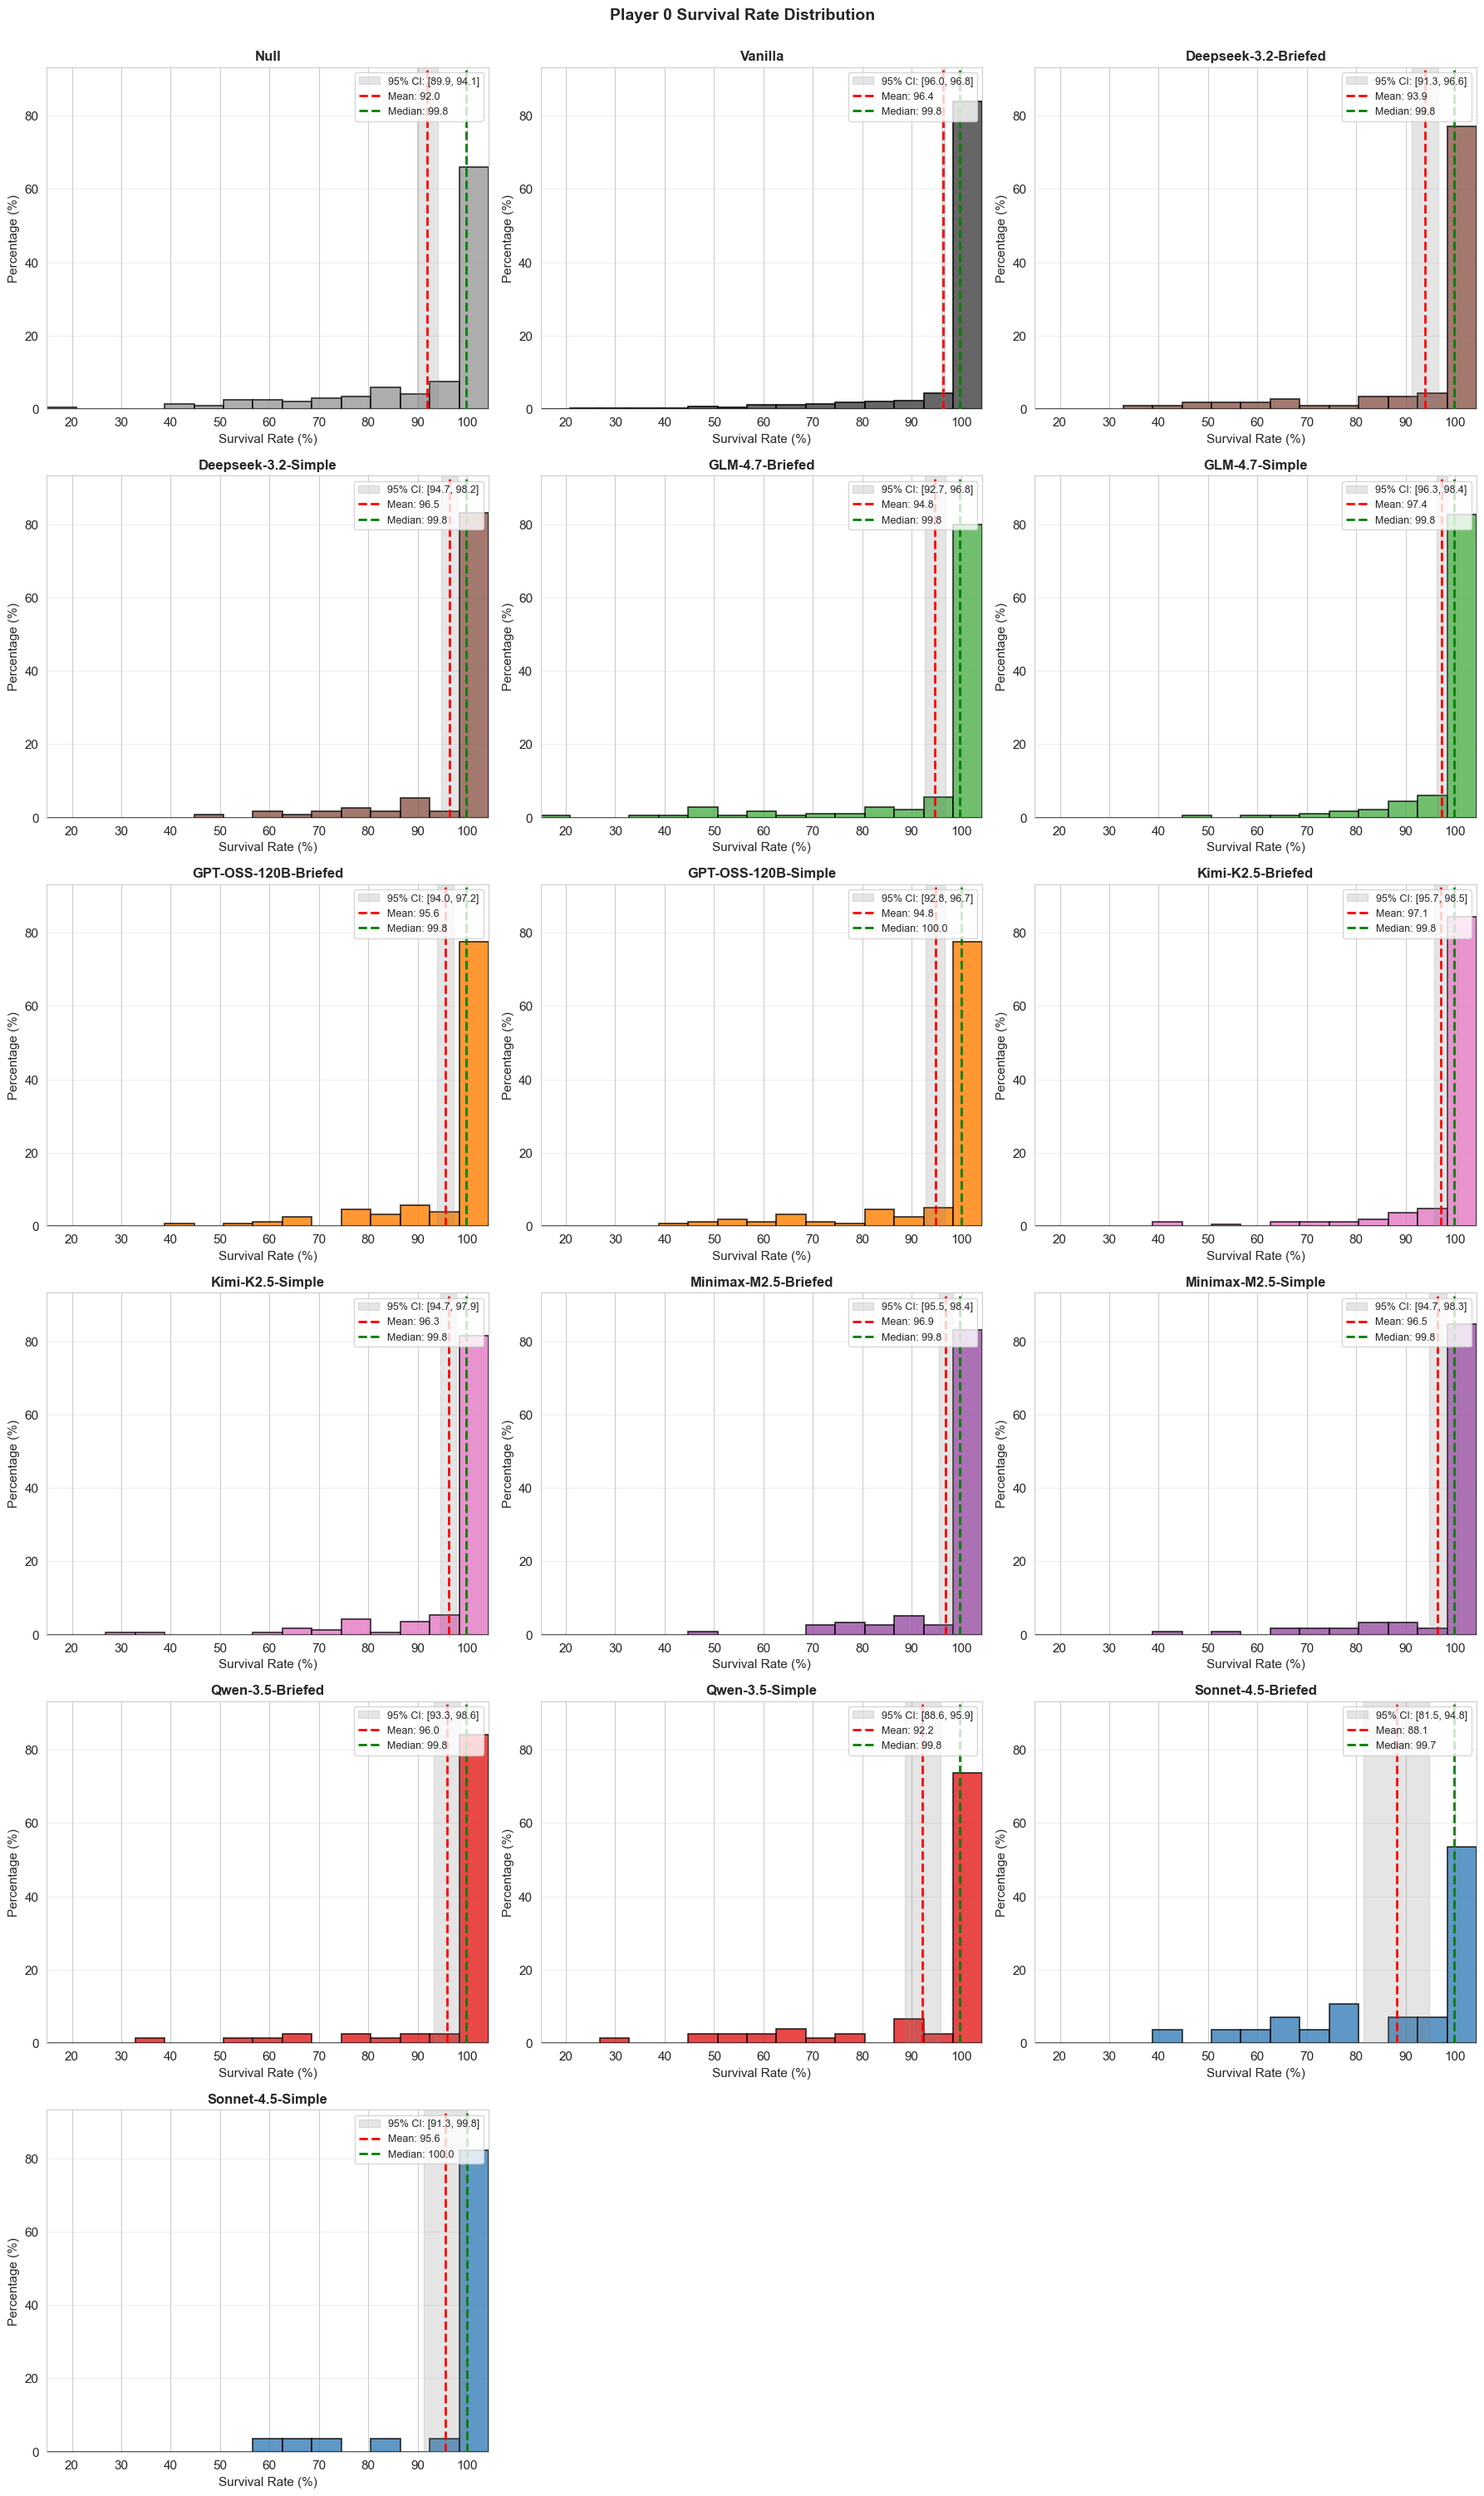


Player 0 Survival Rate Distribution Statistics:


,N,Mean,Median,Std,Min,Max,95% CI
Null,200,91.96,99.80,15.11,19.0,100.2,"[89.85, 94.06]"
Vanilla,2534,96.38,99.77,10.46,22.9,100.3,"[95.97, 96.78]"
Deepseek-3.2-Briefed,113,93.93,99.78,14.33,33.2,100.0,"[91.26, 96.61]"
Deepseek-3.2-Simple,113,96.45,99.79,9.33,48.5,100.0,"[94.71, 98.19]"
GLM-4.7-Briefed,179,94.75,99.78,14.03,19.9,100.0,"[92.68, 96.82]"
GLM-4.7-Simple,179,97.35,99.78,7.29,48.4,100.3,"[96.28, 98.43]"
GPT-OSS-120B-Briefed,156,95.61,99.80,10.20,42.2,100.3,"[94.00, 97.22]"
GPT-OSS-120B-Simple,156,94.77,100.00,12.35,43.7,100.3,"[92.82, 96.73]"
Kimi-K2.5-Briefed,167,97.10,99.79,9.10,39.0,100.0,"[95.71, 98.49]"
Kimi-K2.5-Simple,167,96.27,99.78,10.40,29.8,100.0,"[94.69, 97.86]"


In [46]:
# Calculate survival rate (survival turns / game length)
panel_df['survival_rate'] = panel_df['survival_turn'] / panel_df['turn'] * 100

# Use the reusable function for distribution histograms
plot_distribution_histograms(
    panel_df,
    'survival_rate',
    'Survival Rate (%)',
    'Player 0 Survival Rate Distribution'
)

## 5. Highest Ranking by Condition

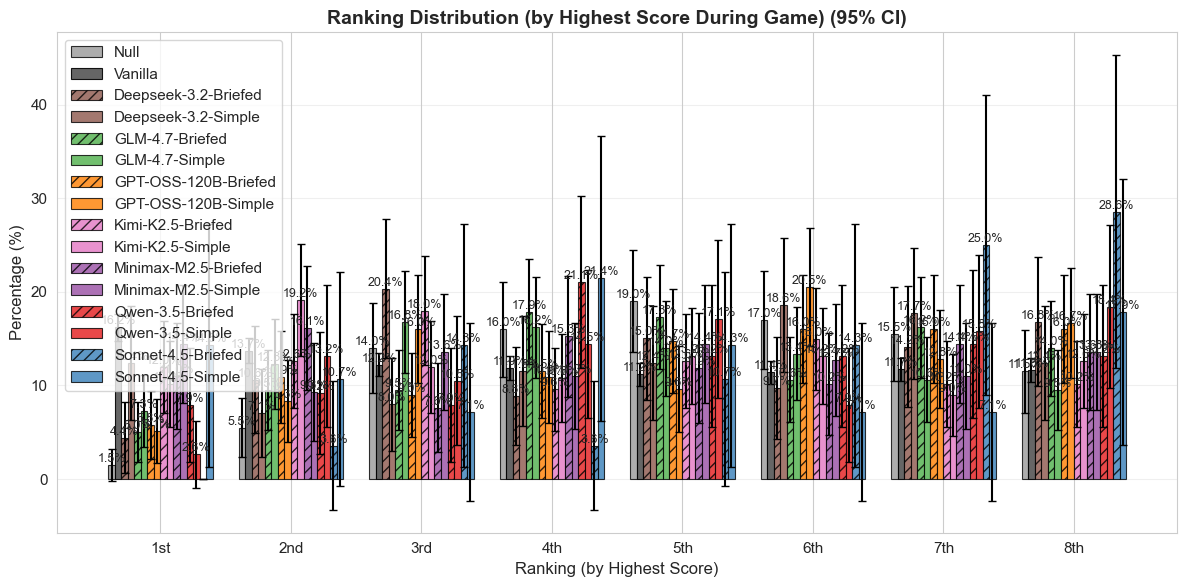

,1st,2nd,3rd,4th,5th,6th,7th,8th
Deepseek-3.2-Briefed,5 (4.4%),12 (10.6%),23 (20.4%),10 (8.8%),17 (15.0%),11 (9.7%),16 (14.2%),19 (16.8%)
Deepseek-3.2-Simple,14 (12.4%),8 (7.1%),9 (8.0%),13 (11.5%),14 (12.4%),21 (18.6%),20 (17.7%),14 (12.4%)
GLM-4.7-Briefed,9 (5.0%),17 (9.5%),17 (9.5%),32 (17.9%),31 (17.3%),19 (10.6%),29 (16.2%),25 (14.0%)
GLM-4.7-Simple,13 (7.3%),22 (12.3%),30 (16.8%),29 (16.2%),25 (14.0%),24 (13.4%),19 (10.6%),17 (9.5%)
GPT-OSS-120B-Briefed,9 (5.8%),17 (10.9%),14 (9.0%),18 (11.5%),23 (14.7%),25 (16.0%),25 (16.0%),25 (16.0%)
GPT-OSS-120B-Simple,8 (5.1%),13 (8.3%),25 (16.0%),17 (10.9%),15 (9.6%),32 (20.5%),20 (12.8%),26 (16.7%)
Kimi-K2.5-Briefed,20 (12.0%),21 (12.6%),30 (18.0%),16 (9.6%),21 (12.6%),25 (15.0%),17 (10.2%),17 (10.2%)
Kimi-K2.5-Simple,17 (10.2%),32 (19.2%),20 (12.0%),18 (10.8%),22 (13.2%),22 (13.2%),15 (9.0%),21 (12.6%)
Minimax-M2.5-Briefed,13 (11.0%),19 (16.1%),9 (7.6%),18 (15.3%),14 (11.9%),12 (10.2%),17 (14.4%),16 (13.6%)
Minimax-M2.5-Simple,17 (14.4%),11 (9.3%),16 (13.6%),13 (11.0%),17 (14.4%),15 (12.7%),13 (11.0%),16 (13.6%)


In [47]:
# Player 0 ranking distribution (based on highest score during game)
plot_grouped_bar_chart(
    panel_df,
    value_col=None,  # Not used when use_percentage=True
    category_col='score_rank',
    xlabel='Ranking (by Highest Score)',
    ylabel='Percentage (%)',
    title='Ranking Distribution (by Highest Score During Game)',
    use_percentage=True,
    show_error_bars=True,
    x_labels=['1st', '2nd', '3rd', '4th', '5th', '6th', '7th', '8th']
)

## 6. Score Ratio Distribution

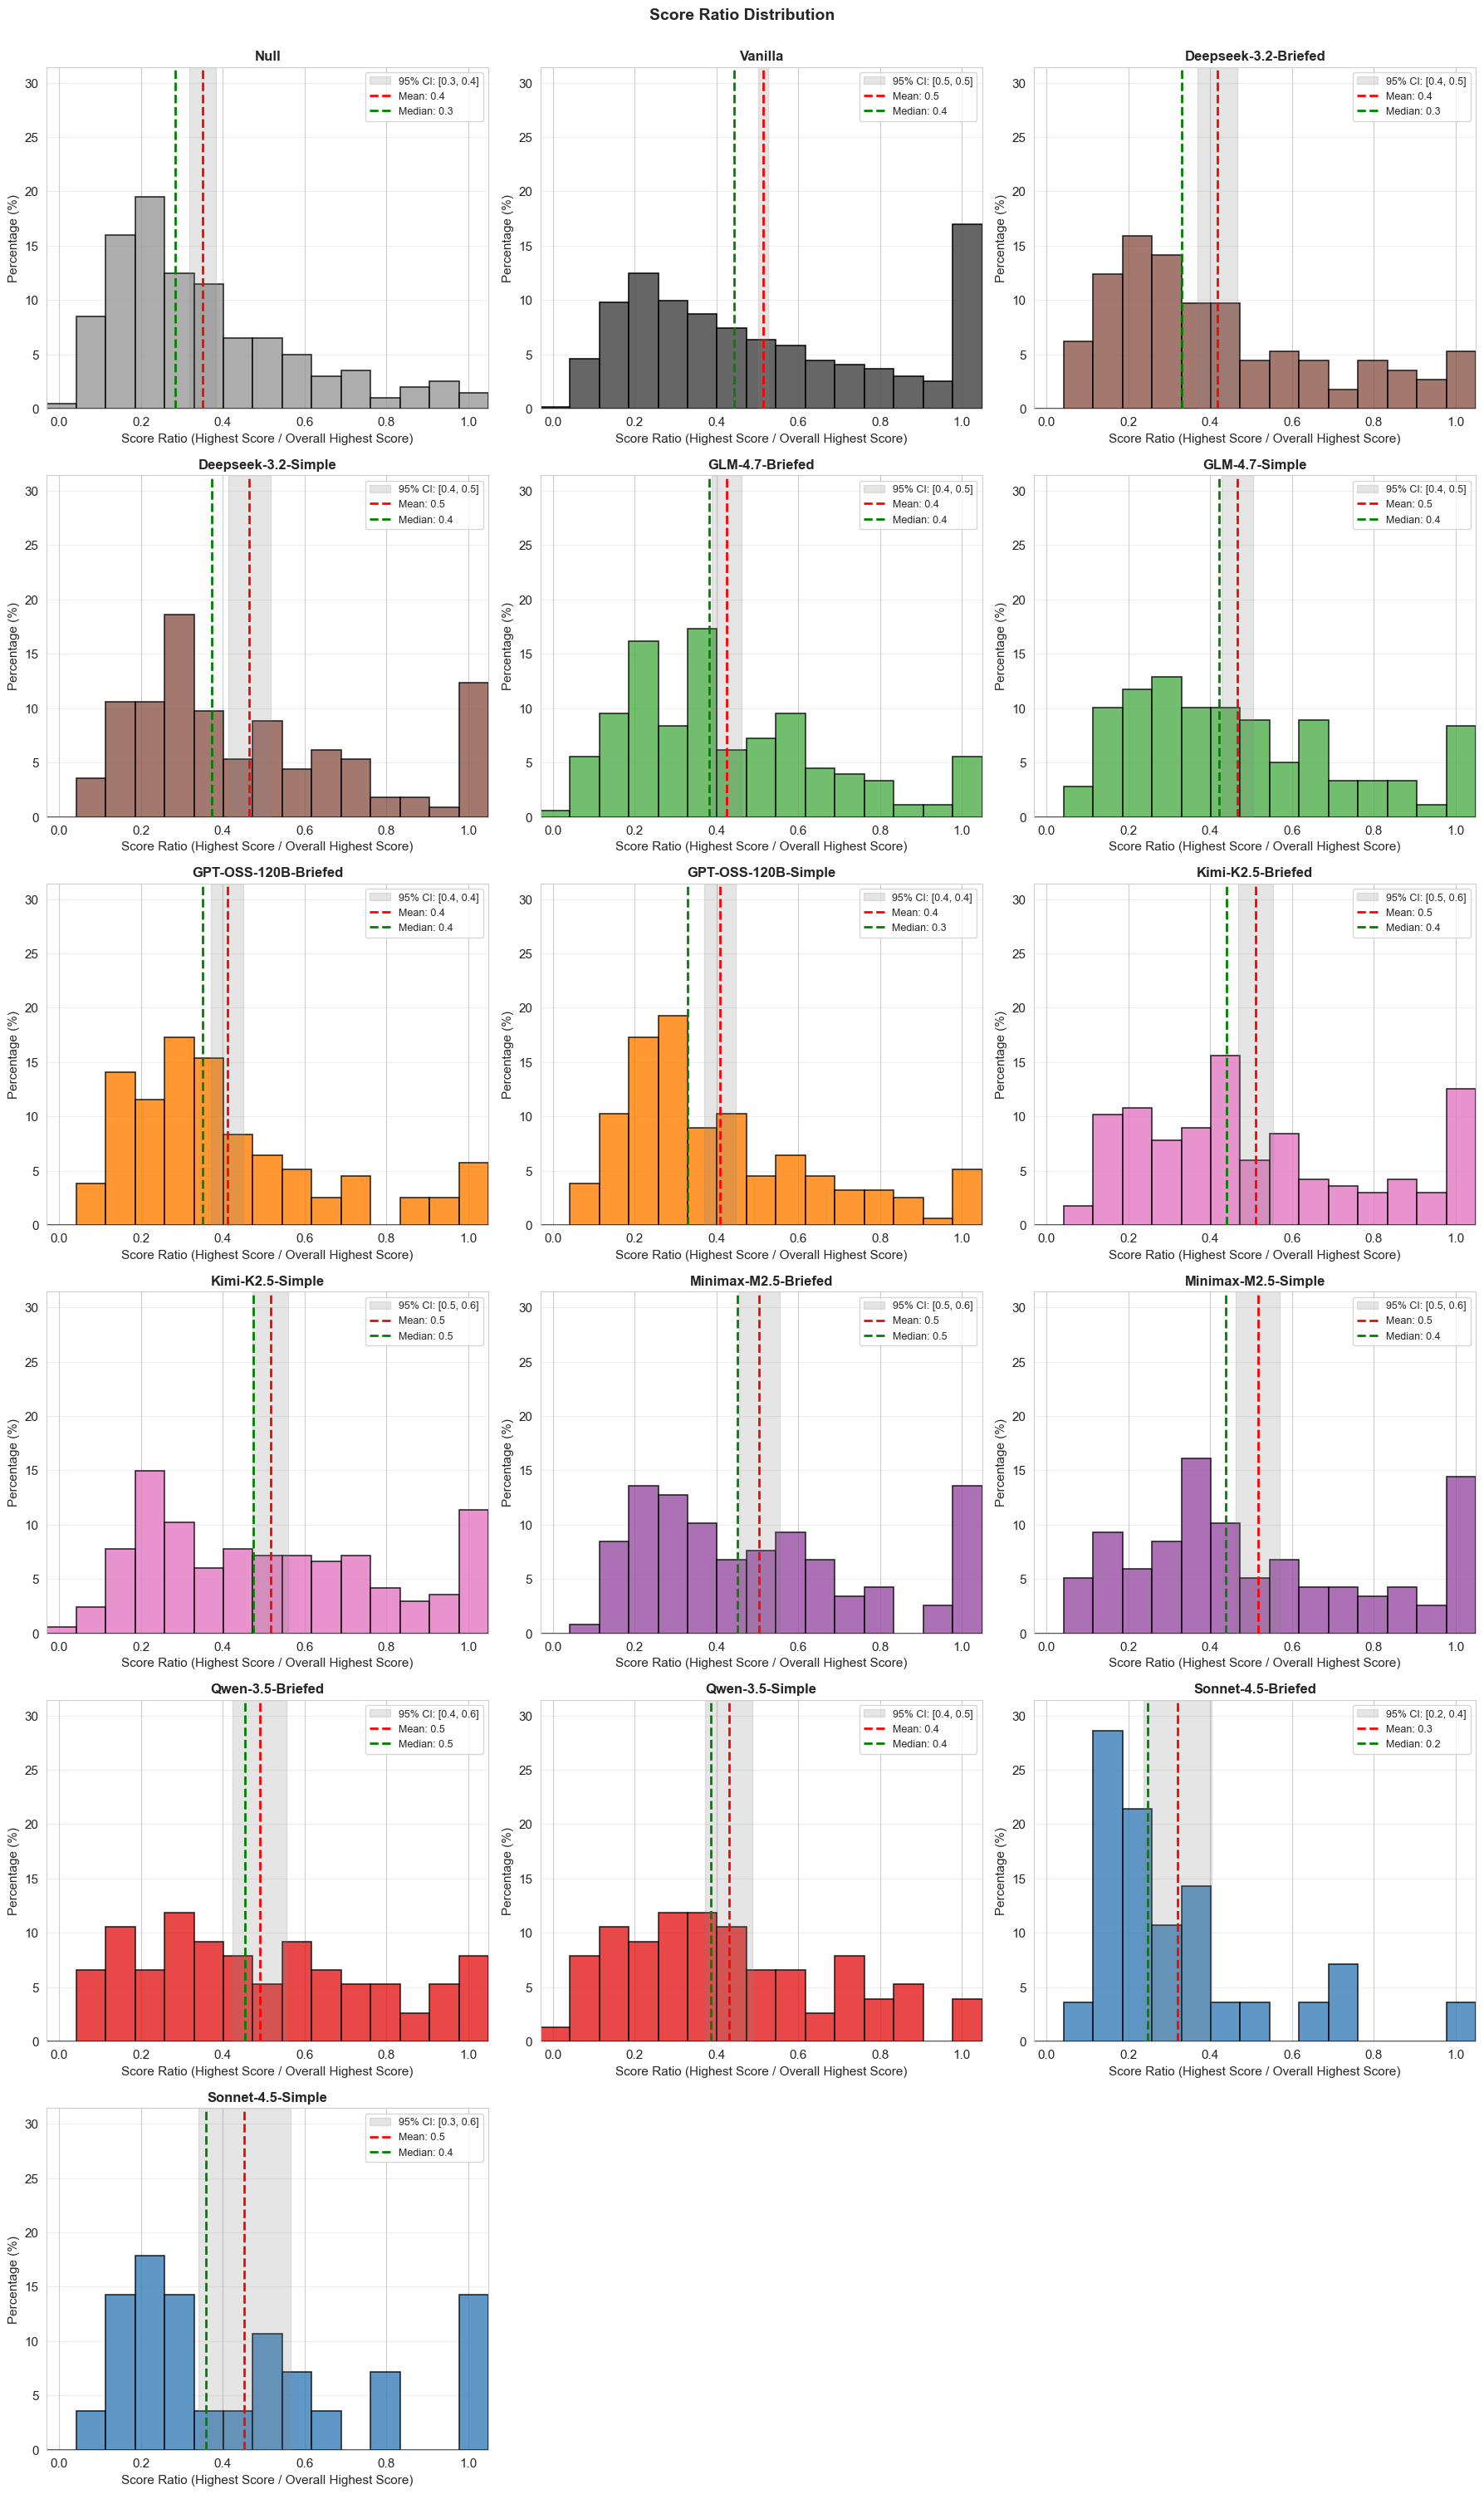


Score Ratio Distribution Statistics:


,N,Mean,Median,Std,Min,Max,95% CI
Null,200,0.35,0.28,0.23,0.0,1.0,"[0.32, 0.38]"
Vanilla,2534,0.51,0.44,0.31,0.0,1.0,"[0.50, 0.53]"
Deepseek-3.2-Briefed,113,0.42,0.33,0.26,0.0,1.0,"[0.37, 0.47]"
Deepseek-3.2-Simple,113,0.46,0.37,0.28,0.1,1.0,"[0.41, 0.52]"
GLM-4.7-Briefed,179,0.42,0.38,0.25,0.0,1.0,"[0.39, 0.46]"
GLM-4.7-Simple,179,0.47,0.42,0.26,0.1,1.0,"[0.43, 0.51]"
GPT-OSS-120B-Briefed,156,0.41,0.35,0.25,0.1,1.0,"[0.37, 0.45]"
GPT-OSS-120B-Simple,156,0.41,0.33,0.24,0.1,1.0,"[0.37, 0.45]"
Kimi-K2.5-Briefed,167,0.51,0.44,0.28,0.1,1.0,"[0.47, 0.55]"
Kimi-K2.5-Simple,167,0.52,0.47,0.29,0.0,1.0,"[0.47, 0.56]"


In [48]:
# Player 0 Score Ratio Distribution
plot_distribution_histograms(
    panel_df, 
    'score_ratio',
    'Score Ratio (Highest Score / Overall Highest Score)',
    'Score Ratio Distribution'
)

## 7. Nuke Behavior: Use-Nuke and Nuke Inclination

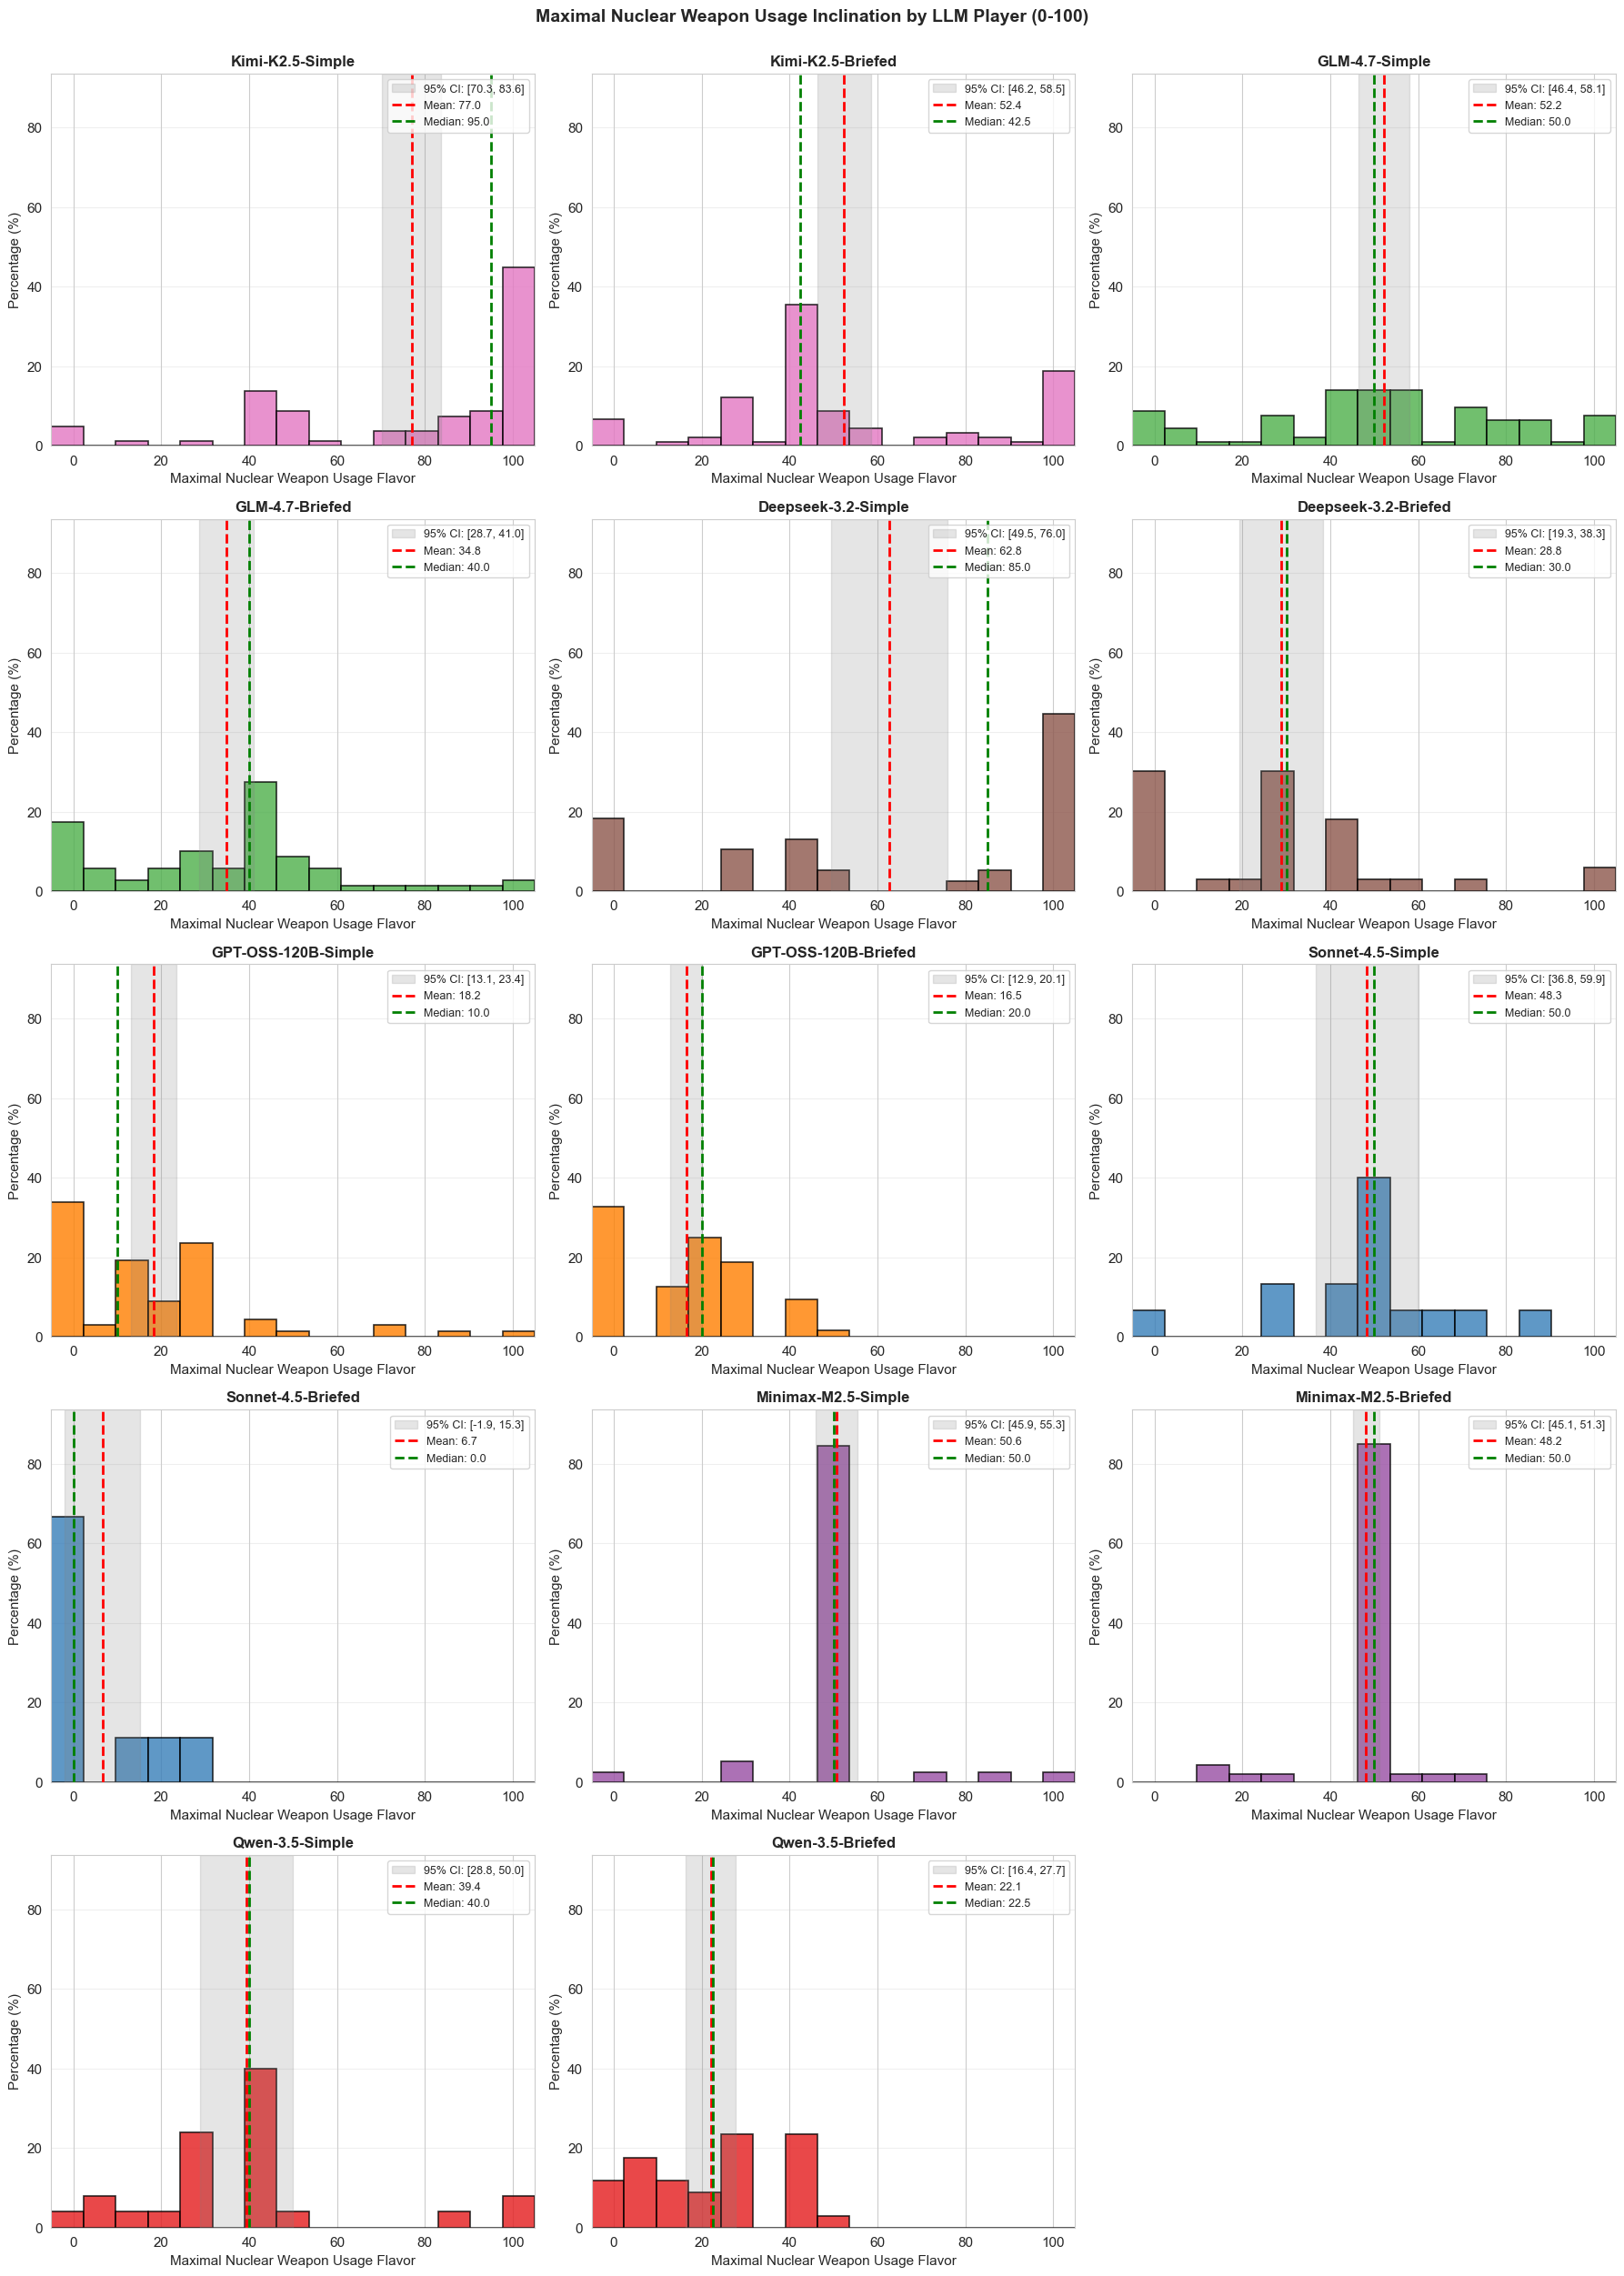


Maximal Nuclear Weapon Usage Inclination by LLM Player (0-100) Statistics:


,N,Mean,Median,Std,Min,Max,95% CI
Kimi-K2.5-Simple,80,76.97,95.0,29.99,0.0,100.0,"[70.30, 83.65]"
Kimi-K2.5-Briefed,90,52.39,42.5,29.32,0.0,100.0,"[46.25, 58.53]"
GLM-4.7-Simple,92,52.25,50.0,28.29,0.0,100.0,"[46.39, 58.11]"
GLM-4.7-Briefed,69,34.83,40.0,25.57,0.0,100.0,"[28.68, 40.97]"
Deepseek-3.2-Simple,38,62.76,85.0,40.25,0.0,100.0,"[49.53, 75.99]"
Deepseek-3.2-Briefed,33,28.79,30.0,26.75,0.0,100.0,"[19.30, 38.27]"
GPT-OSS-120B-Simple,68,18.24,10.0,21.42,0.0,100.0,"[13.05, 23.42]"
GPT-OSS-120B-Briefed,64,16.48,20.0,14.44,0.0,50.0,"[12.88, 20.09]"
Sonnet-4.5-Simple,15,48.33,50.0,20.85,0.0,90.0,"[36.79, 59.88]"
Sonnet-4.5-Briefed,9,6.67,0.0,11.18,0.0,30.0,"[-1.93, 15.26]"


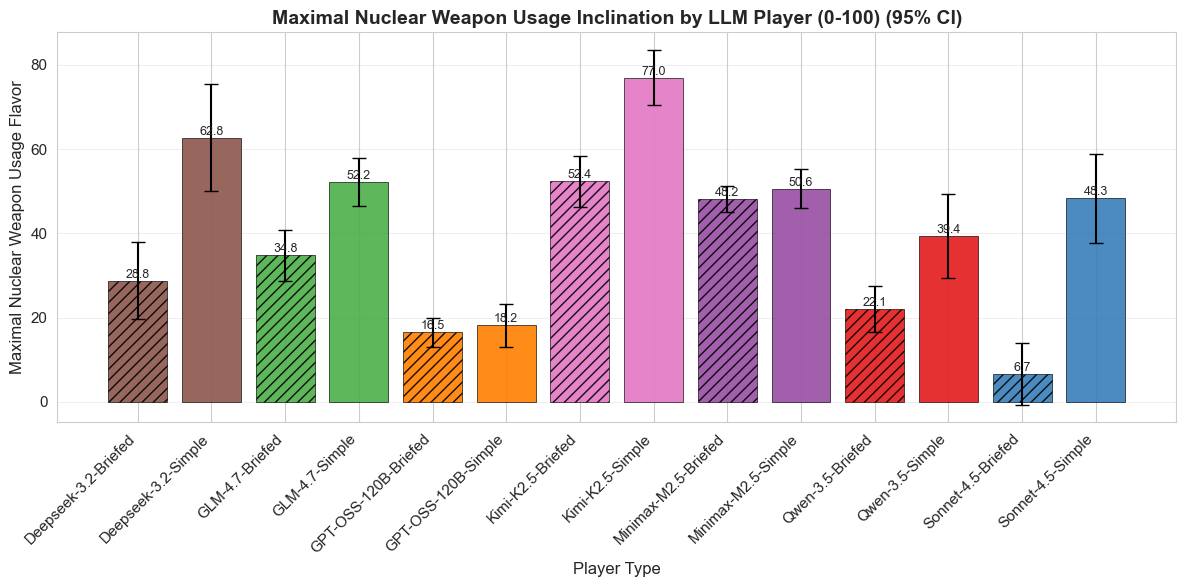

,Mean,Std,N
Deepseek-3.2-Briefed,28.787879,26.752053,33
Deepseek-3.2-Simple,62.763158,40.247501,38
GLM-4.7-Briefed,34.826087,25.567648,69
GLM-4.7-Simple,52.250000,28.289953,92
GPT-OSS-120B-Briefed,16.484375,14.438696,64
GPT-OSS-120B-Simple,18.235294,21.419142,68
Kimi-K2.5-Briefed,52.388889,29.320275,90
Kimi-K2.5-Simple,76.975000,29.987751,80
Minimax-M2.5-Briefed,48.191489,10.499769,47
Minimax-M2.5-Simple,50.641026,14.517661,39


In [49]:
# Filter to LLM players only (exclude Vanilla)
llm_players = [pt for pt in panel_df['player_type'].unique() if pt != 'Vanilla' and pt != 'Null']

plot_distribution_histograms(
    panel_df,
    'use_nuke',
    'Maximal Nuclear Weapon Usage Flavor',
    'Maximal Nuclear Weapon Usage Inclination by LLM Player (0-100)',
    player_type_filter=llm_players
)

# Bar chart version with model-based colors
plot_bar_chart(
    panel_df[panel_df['player_type'].isin(llm_players)],
    value_col='use_nuke',
    category_col='player_type',
    xlabel='Player Type',
    ylabel='Maximal Nuclear Weapon Usage Flavor',
    title='Maximal Nuclear Weapon Usage Inclination by LLM Player (0-100)',
    figsize=(12,6),
    use_percentage=False,
    show_error_bars=True,
    color_by_category=True
)

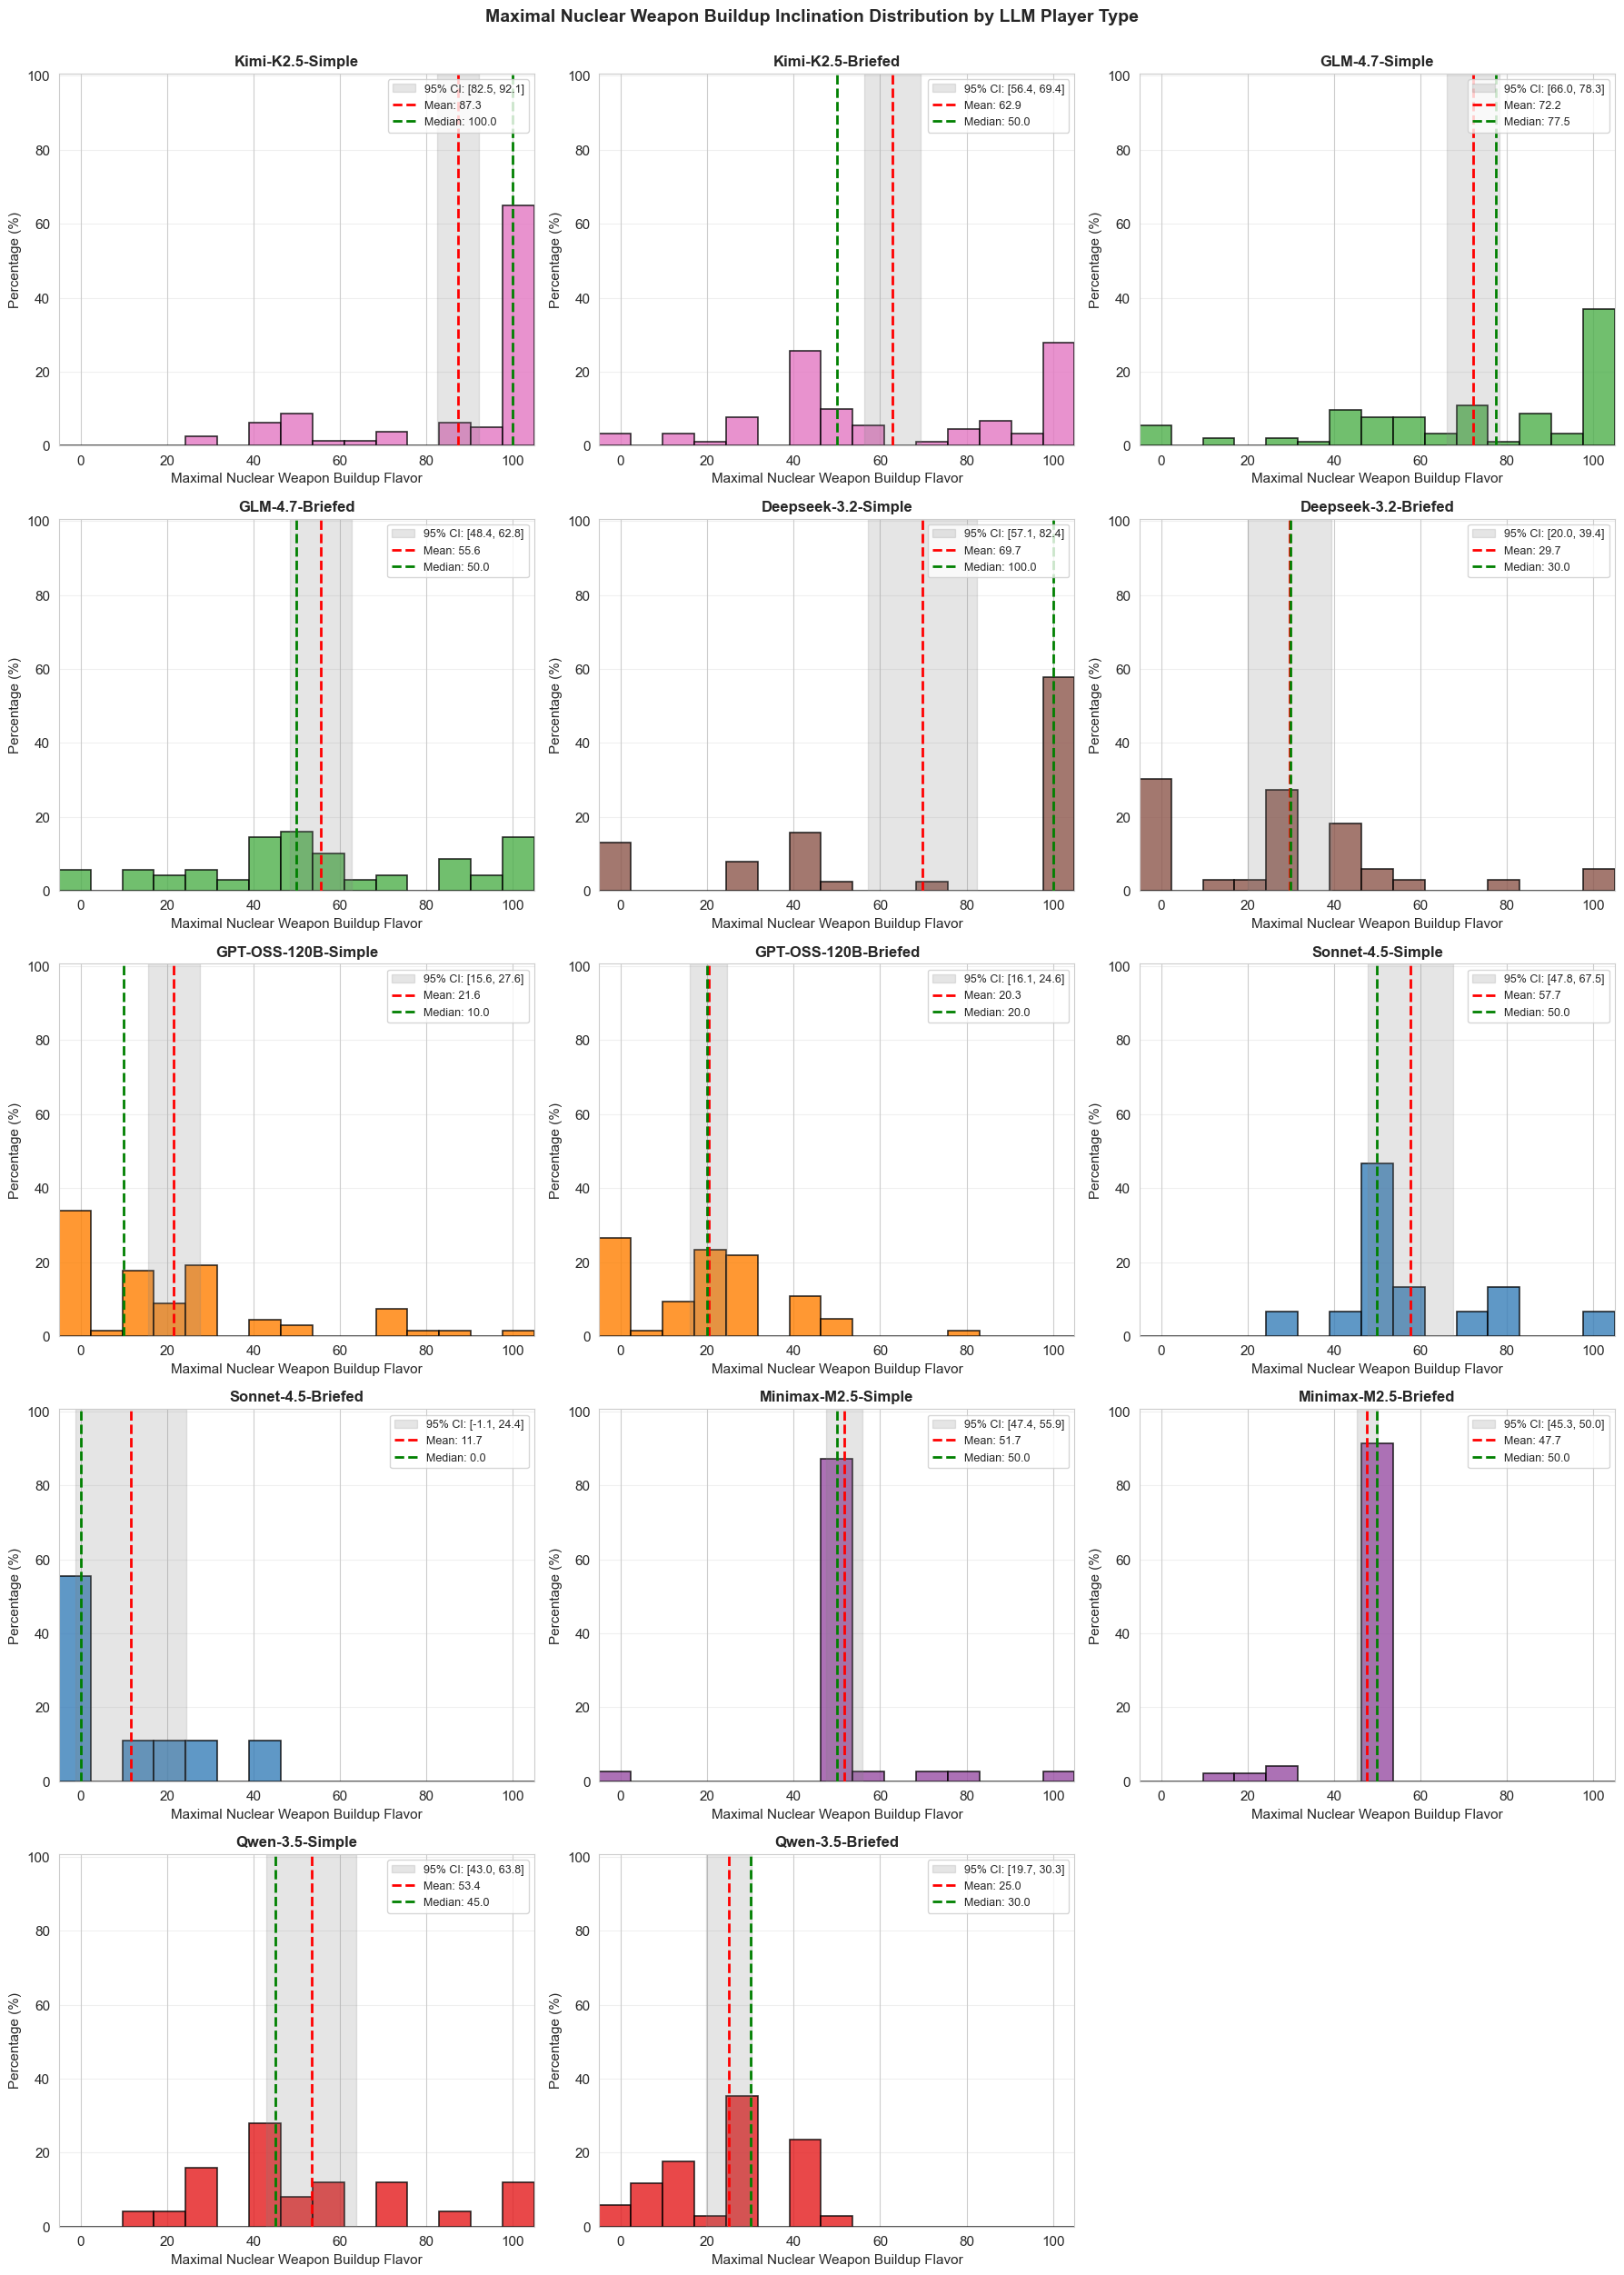


Maximal Nuclear Weapon Buildup Inclination Distribution by LLM Player Type Statistics:


,N,Mean,Median,Std,Min,Max,95% CI
Kimi-K2.5-Simple,80,87.31,100.0,21.58,30.0,100.0,"[82.51, 92.12]"
Kimi-K2.5-Briefed,90,62.89,50.0,30.94,0.0,100.0,"[56.41, 69.37]"
GLM-4.7-Simple,92,72.17,77.5,29.80,0.0,100.0,"[66.00, 78.35]"
GLM-4.7-Briefed,69,55.61,50.0,30.04,0.0,100.0,"[48.39, 62.82]"
Deepseek-3.2-Simple,38,69.74,100.0,38.52,0.0,100.0,"[57.08, 82.40]"
Deepseek-3.2-Briefed,33,29.70,30.0,27.36,0.0,100.0,"[20.00, 39.40]"
GPT-OSS-120B-Simple,68,21.62,10.0,24.88,0.0,100.0,"[15.60, 27.64]"
GPT-OSS-120B-Briefed,64,20.31,20.0,17.06,0.0,80.0,"[16.05, 24.57]"
Sonnet-4.5-Simple,15,57.67,50.0,17.82,30.0,100.0,"[47.80, 67.53]"
Sonnet-4.5-Briefed,9,11.67,0.0,16.58,0.0,45.0,"[-1.08, 24.41]"


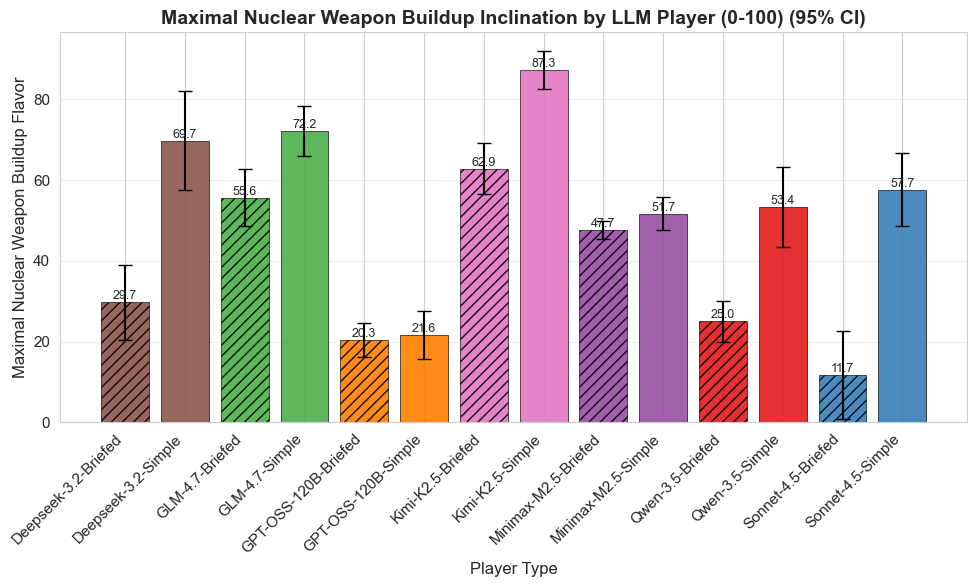

,Mean,Std,N
Deepseek-3.2-Briefed,29.696970,27.355855,33
Deepseek-3.2-Simple,69.736842,38.518991,38
GLM-4.7-Briefed,55.608696,30.036359,69
GLM-4.7-Simple,72.173913,29.800660,92
GPT-OSS-120B-Briefed,20.312500,17.063723,64
GPT-OSS-120B-Simple,21.617647,24.879428,68
Kimi-K2.5-Briefed,62.888889,30.940118,90
Kimi-K2.5-Simple,87.312500,21.582103,80
Minimax-M2.5-Briefed,47.659574,8.132802,47
Minimax-M2.5-Simple,51.666667,13.095466,39


In [50]:
plot_distribution_histograms(
    panel_df,
    'nuke',
    'Maximal Nuclear Weapon Buildup Flavor',
    'Maximal Nuclear Weapon Buildup Inclination Distribution by LLM Player Type',
    player_type_filter=llm_players
)

# Bar chart version with model-based colors
plot_bar_chart(
    panel_df[panel_df['player_type'].isin(llm_players)],
    value_col='nuke',
    category_col='player_type',
    xlabel='Player Type',
    ylabel='Maximal Nuclear Weapon Buildup Flavor',
    title='Maximal Nuclear Weapon Buildup Inclination by LLM Player (0-100)',
    use_percentage=False,
    show_error_bars=True,
    color_by_category=True
)